# UK Used Car Price Prediction

**Problem:** buyers and dealers need a fair price for a used car from its basic details. This project studies what drives used car prices in the UK and builds a model that estimates a price from make, model, age, mileage and specification.

**Data:** 97,712 used car listings from nine manufacturers (Audi, BMW, Ford, Hyundai, Mercedes, Skoda, Toyota, Vauxhall, Volkswagen), based on the [100,000 UK Used Car Data set](https://www.kaggle.com/datasets/adityadesai13/used-car-dataset-ford-and-mercedes) on Kaggle. The listings were collected in 2020.

**Target:** `price` in pounds.

## 1. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from src.analysis import (
    TARGET, DATA_YEAR, load_raw, clean, missing_report, price_by, depreciation_curve,
    depreciation_by_manufacturer, plot_price_distribution, plot_depreciation, plot_mileage_vs_price,
    plot_price_by_manufacturer, plot_price_by_category, plot_correlations,
)
from src.model import (
    FEATURES, compare_models, cross_validate_final, leakage_demo, test_predictions, error_by,
    feature_importance, plot_model_comparison, plot_actual_vs_predicted, plot_feature_importance,
)

FIGURES = ROOT / "reports" / "figures"
RESULTS = ROOT / "reports"
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140)

def save(fig, name):
    fig.savefig(FIGURES / name, dpi=120, bbox_inches="tight")
    plt.show()

## 2. Load and inspect

In [2]:
raw = load_raw()
print(raw.shape)
raw.head()

(97712, 10)


,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Manufacturer
0,I10,2017,7495.0,Manual,11630,Petrol,145,60.1,1.0,hyundi
1,Polo,2017,10989.0,Manual,9200,Petrol,145,58.9,1.0,volkswagen
2,2 Series,2019,27990.0,Semi-Auto,1614,Diesel,145,49.6,2.0,BMW
3,Yeti Outdoor,2017,12495.0,Manual,30960,Diesel,150,62.8,2.0,skoda
4,Fiesta,2017,7999.0,Manual,19353,Petrol,125,54.3,1.2,ford


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 97712 entries, 0 to 97711
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         97712 non-null  str    
 1   year          97712 non-null  int64  
 2   price         96727 non-null  float64
 3   transmission  97712 non-null  str    
 4   mileage       97712 non-null  int64  
 5   fuelType      93586 non-null  str    
 6   tax           97712 non-null  int64  
 7   mpg           94256 non-null  float64
 8   engineSize    97712 non-null  float64
 9   Manufacturer  97712 non-null  str    
dtypes: float64(3), int64(3), str(4)
memory usage: 9.8 MB


In [4]:
raw.describe().round(1)

,year,price,mileage,tax,mpg,engineSize
count,97712.0,96727.0,97712.0,97712.0,94256.0,97712.0
mean,2017.1,16774.3,23219.5,120.1,55.2,1.7
std,2.1,9874.7,21060.9,63.4,16.3,0.6
min,1970.0,450.0,1.0,0.0,0.3,0.0
25%,2016.0,9999.0,7673.0,125.0,47.1,1.2
50%,2017.0,14471.0,17682.5,145.0,54.3,1.6
75%,2019.0,20750.0,32500.0,145.0,62.8,2.0
max,2024.0,159999.0,323000.0,580.0,470.8,6.6


In [5]:
print("Missing values:")
print(raw.isna().sum())
print()
print("Manufacturer labels:", sorted(raw["Manufacturer"].unique()))
print("Registration years above", DATA_YEAR, ":", int((raw["year"] > DATA_YEAR).sum()))
print("Engine size of 0:", int((raw["engineSize"] == 0).sum()))

Missing values:
model              0
year               0
price            985
transmission       0
mileage            0
fuelType        4126
tax                0
mpg             3456
engineSize         0
Manufacturer       0
dtype: int64

Manufacturer labels: ['Audi', 'BMW', 'ford', 'hyundi', 'merc', 'skoda', 'toyota', 'vauxhall', 'volkswagen']
Registration years above 2020 : 1
Engine size of 0: 268


## 3. Cleaning

| Issue | Action |
|---|---|
| 985 listings have no price | Dropped, because the model cannot learn from them |
| One car registered in 2024, in data collected in 2020 | Dropped as an entry error |
| Manufacturer labels `hyundi` and `merc` | Renamed to Hyundai and Mercedes |
| Model names start with a space | Trimmed |
| Engine size of 0 on non-electric cars | Treated as missing |
| Missing fuel type, mpg and engine size | Filled inside the model pipeline with the most frequent value or the median, learned from training data only |
| Registration year | Converted to age in 2020 |

Price outliers are **kept**. Expensive cars are genuine listings, and the first version of this project removed 38% of all rows by filtering outliers in every column one after another, including the price itself.

In [6]:
df, cleaning_log = clean(raw)
cleaning_log

,step,rows,removed
0,Raw rows,97712,0
1,After dropping rows with no price,96727,985
2,After dropping exact duplicates,96727,0
3,After dropping cars registered after 2020,96726,1


In [7]:
missing_report(df)

,missing,missing_%
fuelType,3141,3.25
mpg,2471,2.55
engineSize,260,0.27


## 4. Price distribution

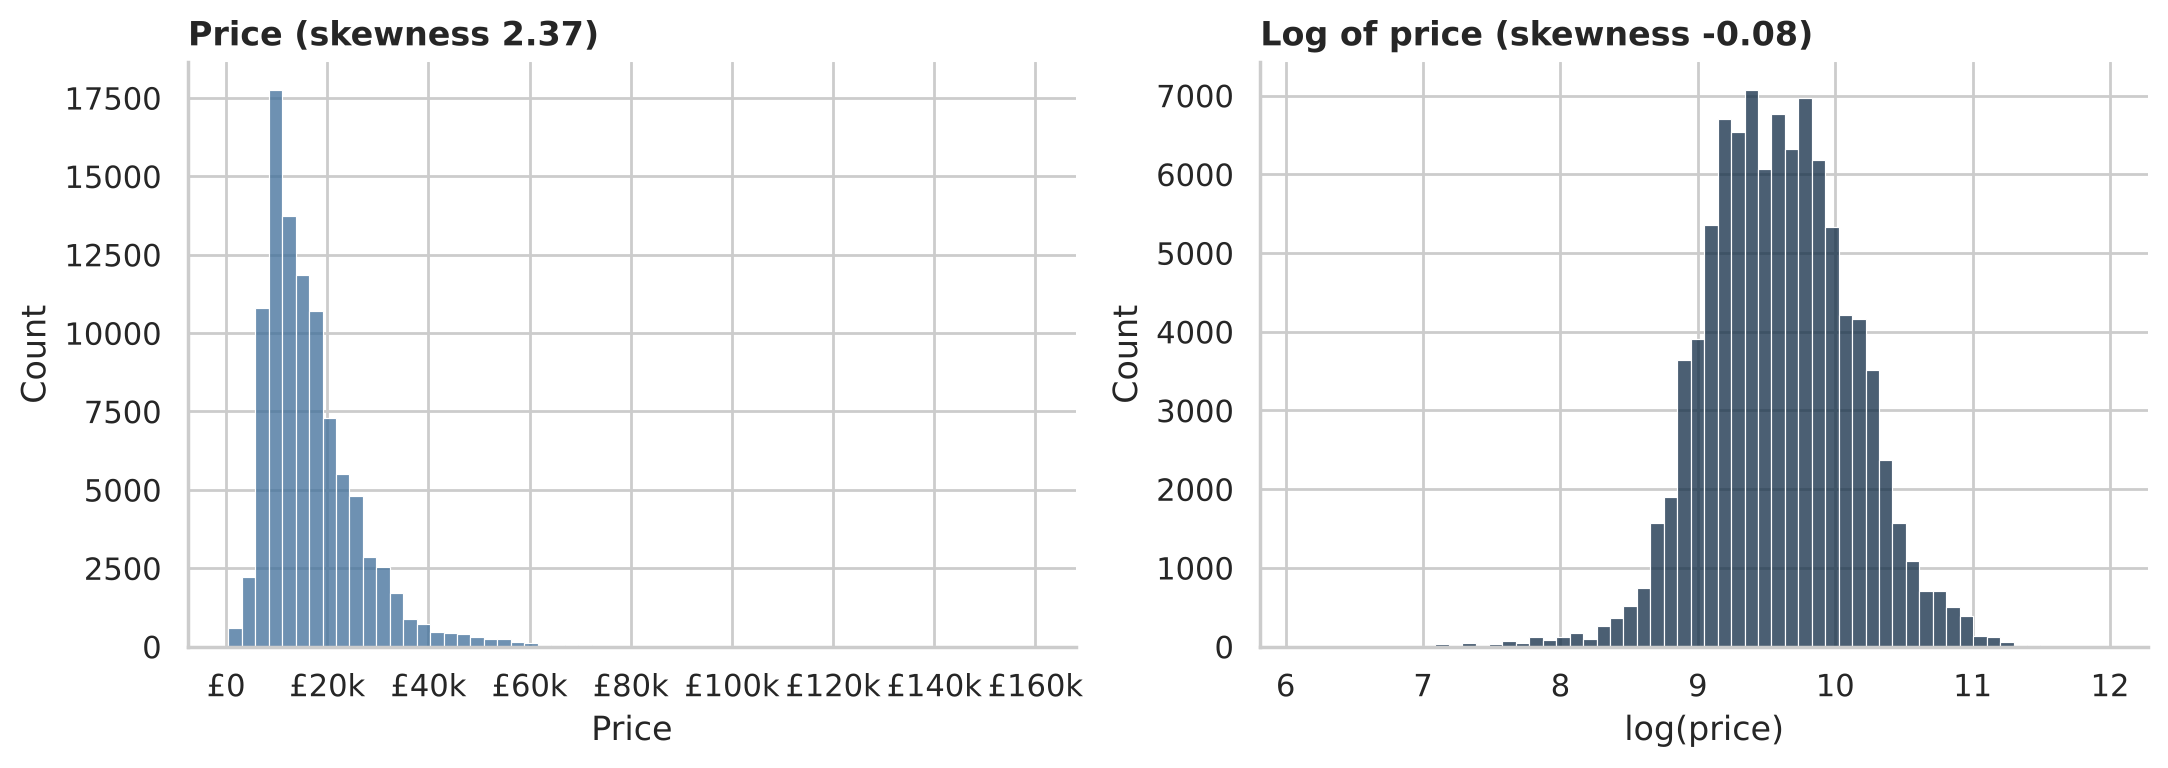

In [8]:
save(plot_price_distribution(df), "price_distribution.png")

Prices are right-skewed (skewness 2.37). The log of price is almost symmetric, so the models are trained on log(price) and their predictions converted back to pounds.

## 5. What drives the price

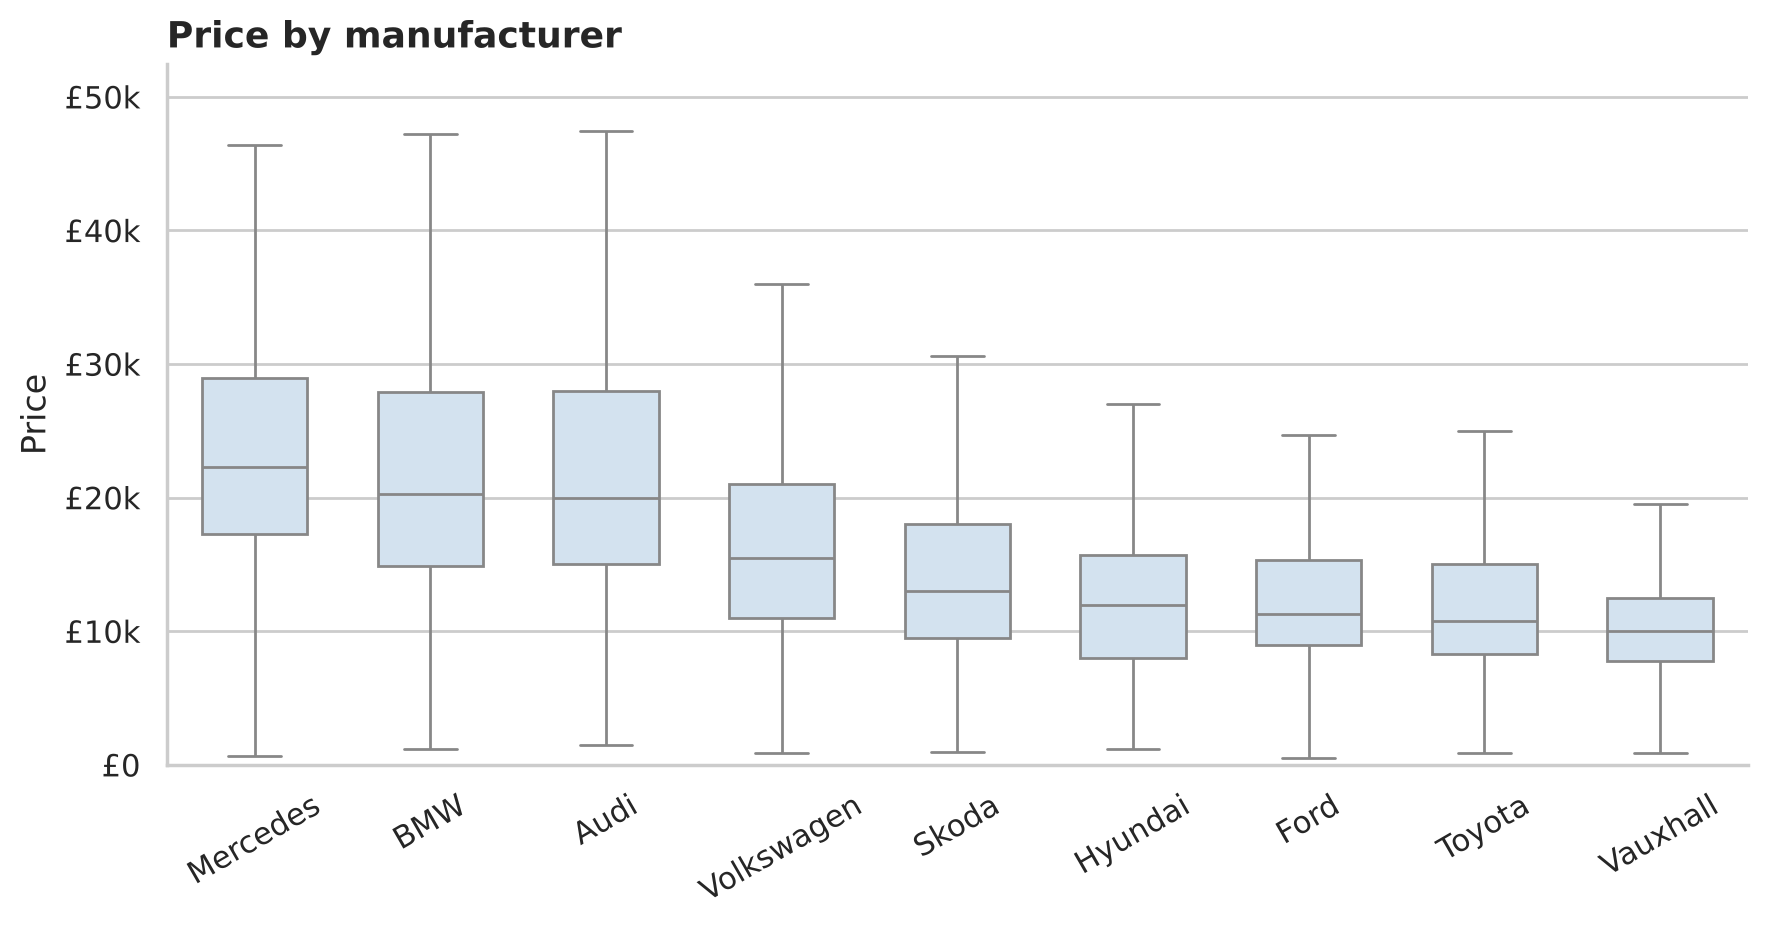

In [9]:
save(plot_price_by_manufacturer(df), "price_by_manufacturer.png")

In [10]:
price_by(df, "Manufacturer")

,Manufacturer,listings,median_price,mean_price
0,Mercedes,12737,22299.0,24637.0
1,BMW,10563,20250.0,22704.0
2,Audi,10453,20000.0,22835.0
3,Volkswagen,14740,15490.0,16806.0
4,Skoda,6131,12998.0,14293.0
5,Hyundai,4730,11990.0,12724.0
6,Ford,17627,11287.0,12269.0
7,Toyota,6626,10796.5,12537.0
8,Vauxhall,13119,9998.0,10315.0


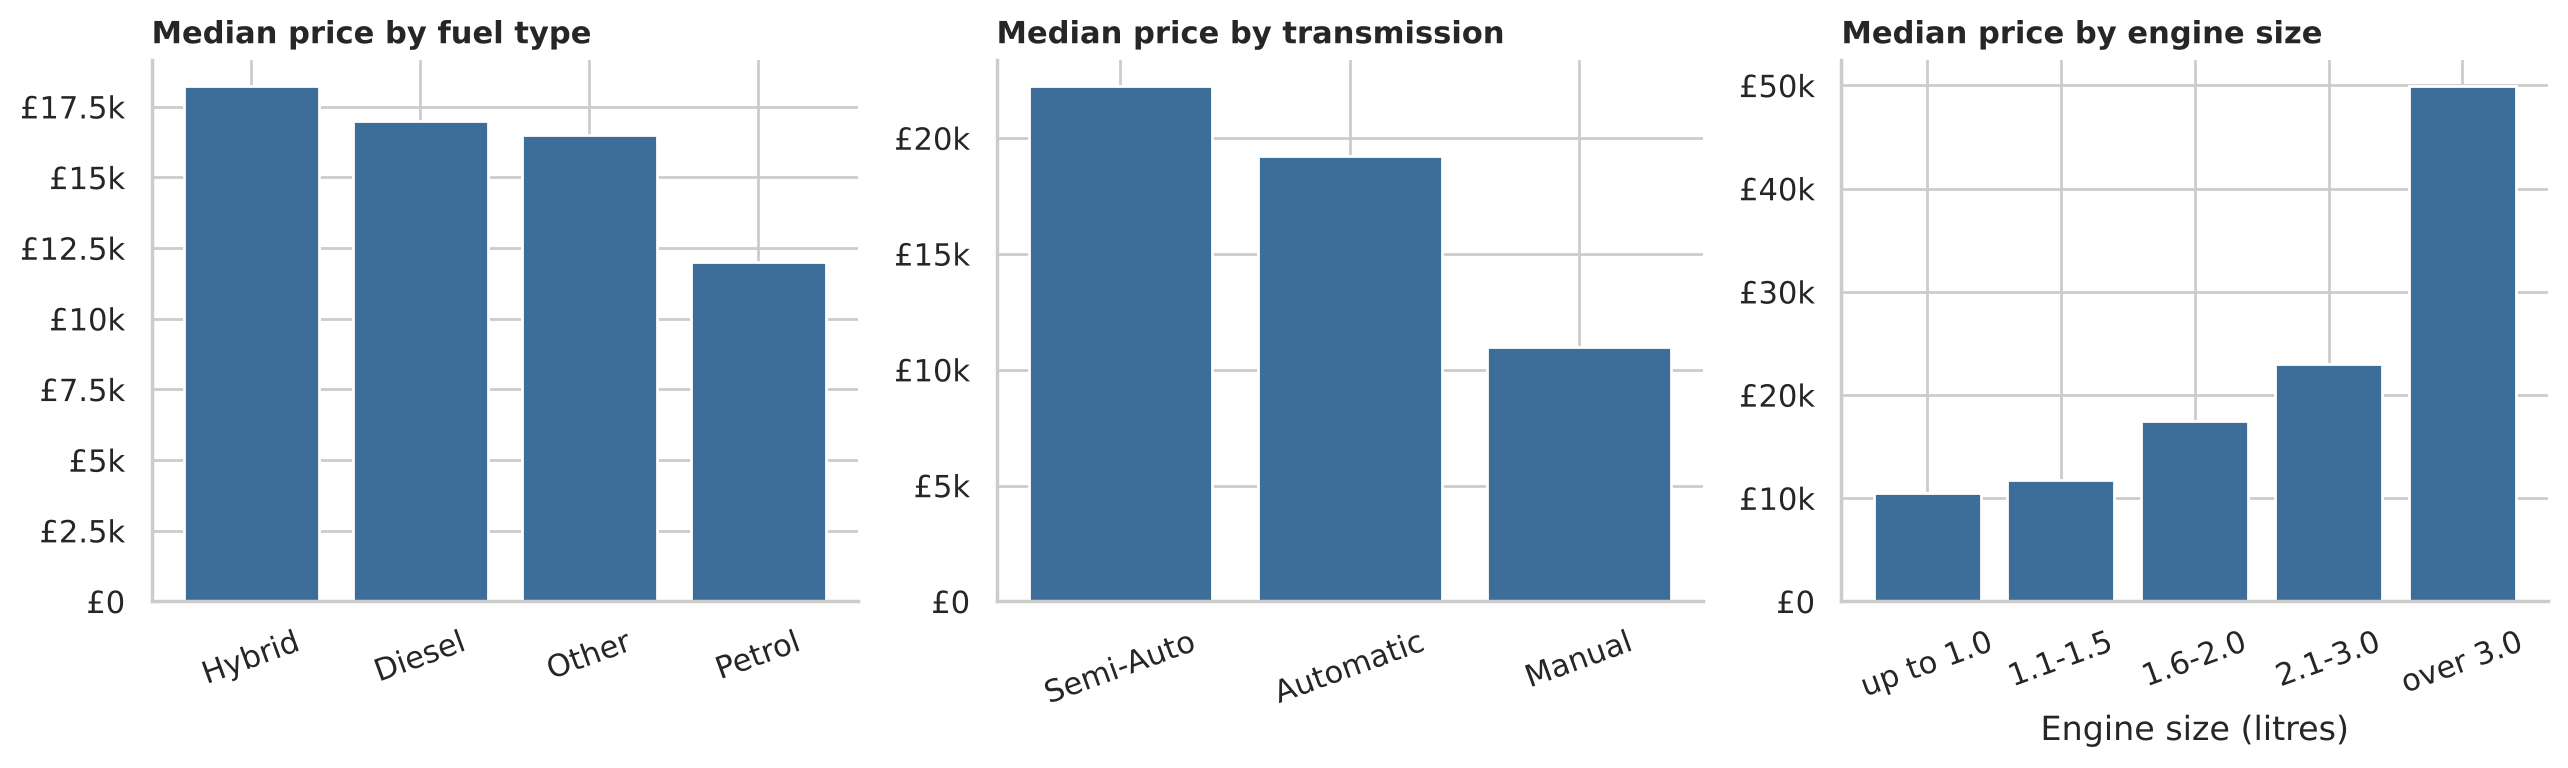

In [11]:
save(plot_price_by_category(df), "price_by_fuel_transmission_engine.png")

In [12]:
display(price_by(df, "fuelType", min_count=50))
display(price_by(df, "transmission", min_count=50))

,fuelType,listings,median_price,mean_price
0,Hybrid,2938,18248.5,19265.0
1,Diesel,38696,17000.0,19307.0
2,Other,241,16500.0,17505.0
3,Petrol,51705,11998.0,14730.0


,transmission,listings,median_price,mean_price
0,Semi-Auto,22071,22265.0,24236.0
1,Automatic,19697,19250.0,21525.0
2,Manual,54949,11000.0,12075.0


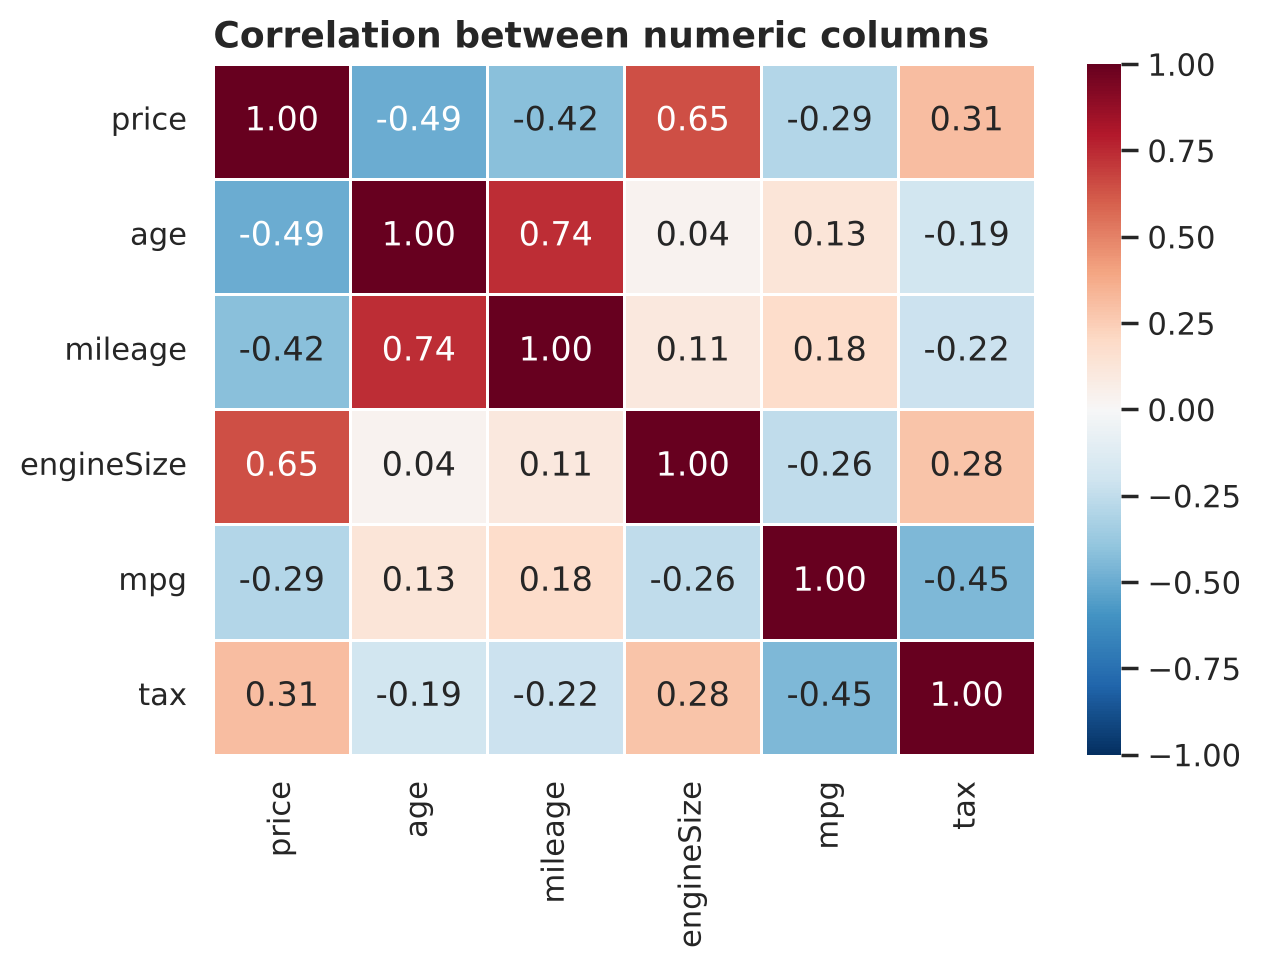

In [13]:
save(plot_correlations(df), "correlations.png")

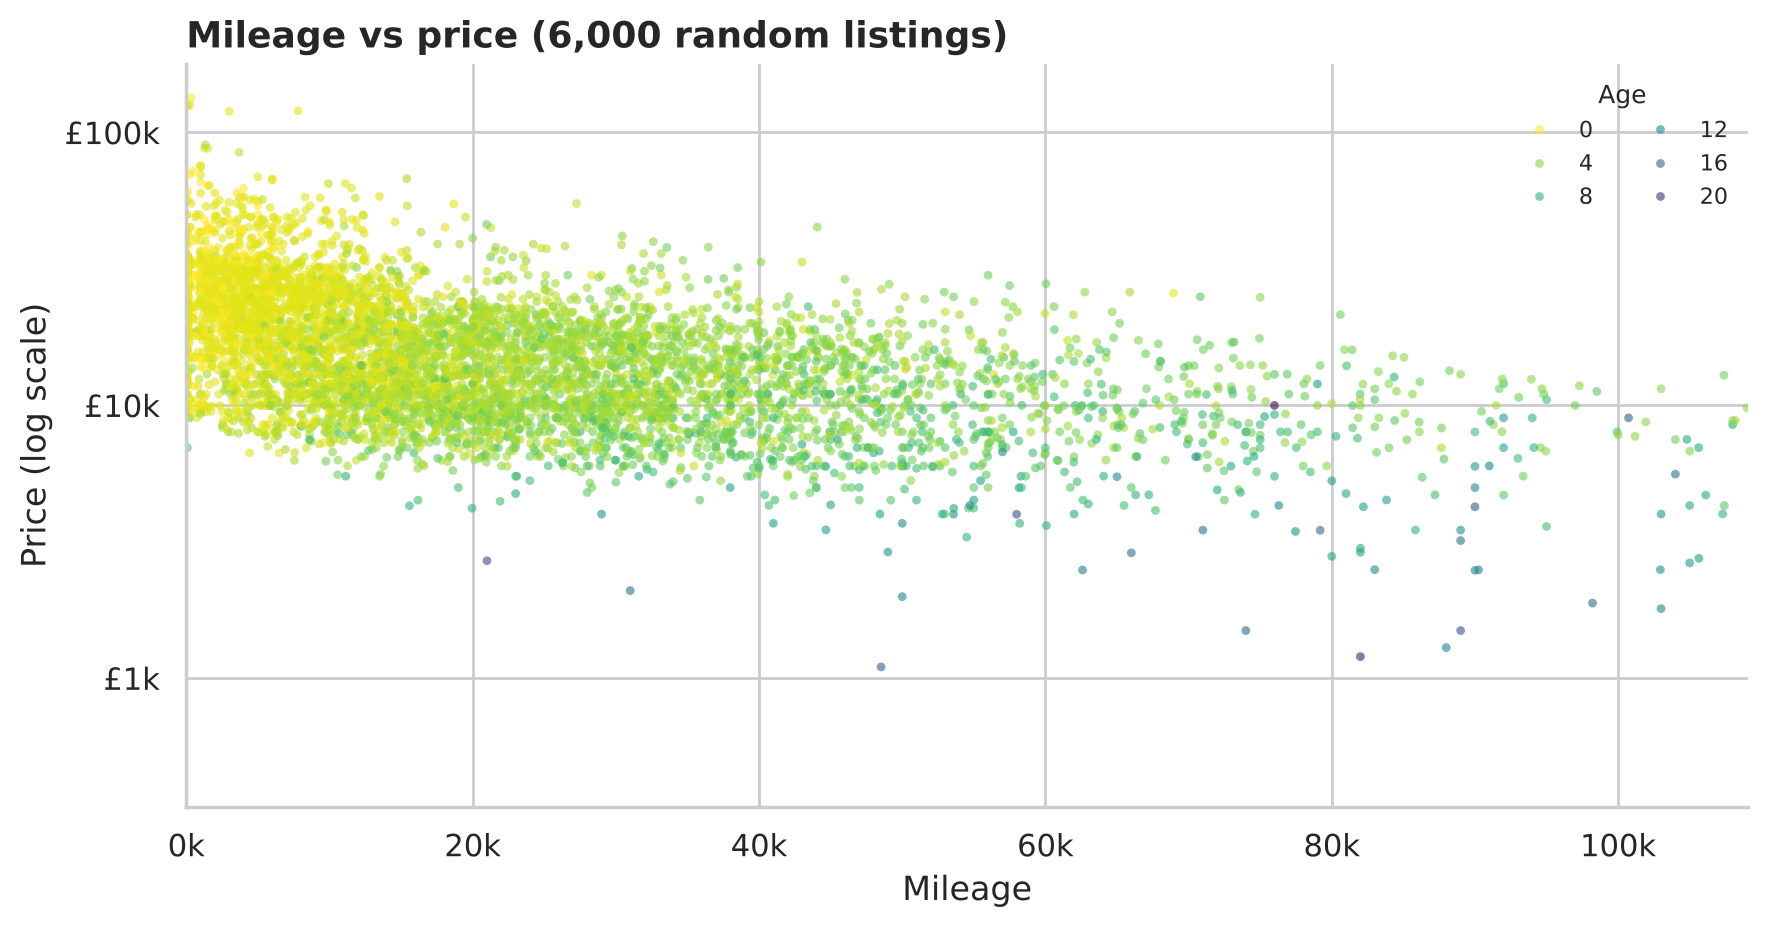

In [14]:
save(plot_mileage_vs_price(df), "mileage_vs_price.png")

Engine size has the strongest link with price (0.65). Age and mileage both lower the price and are closely linked to each other (0.74), since older cars have usually covered more miles.

## 6. Depreciation

In [15]:
depreciation_curve(df)

,age,listings,median_price,value_kept_%
0,0,4009,26990.0,100.0
1,1,25884,21990.0,81.5
2,2,13429,14095.0,52.2
3,3,21403,12825.0,47.5
4,4,15576,11999.0,44.5
5,5,7515,10490.0,38.9
6,6,4014,8995.0,33.3
7,7,2561,7820.0,29.0
8,8,622,6990.0,25.9
9,9,427,5499.0,20.4


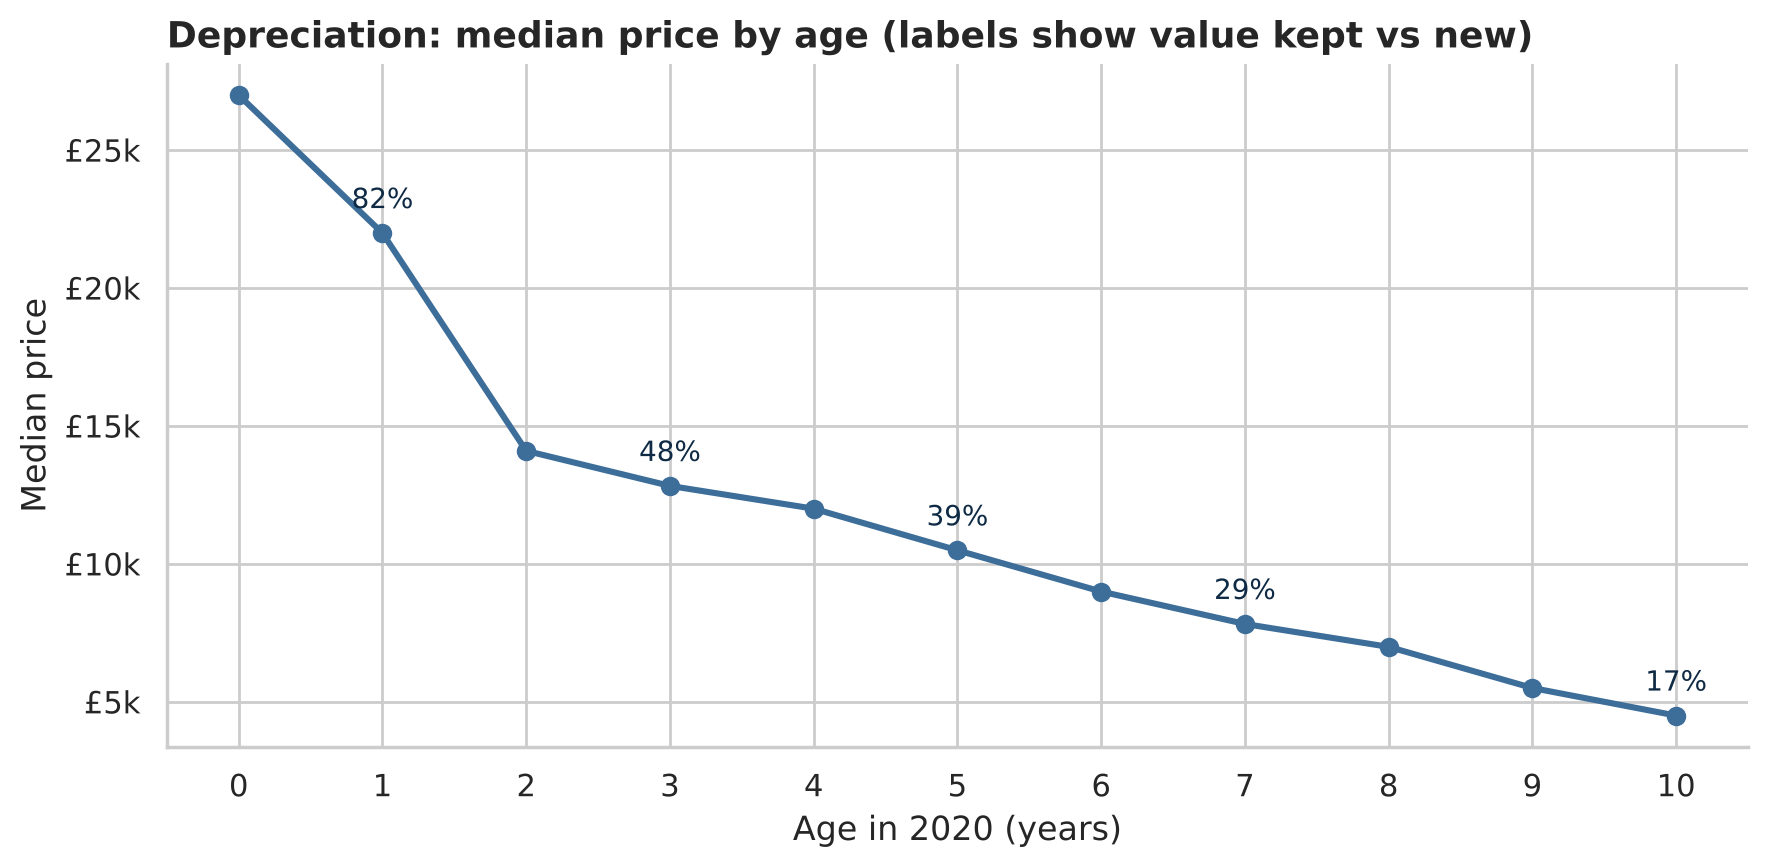

In [16]:
save(plot_depreciation(df), "depreciation.png")

In [17]:
depreciation_by_manufacturer(df)

,Manufacturer,age_0,age_3,age_5,value_kept_after_3y_%,value_kept_after_5y_%
0,Vauxhall,15990.0,10300.0,7298.0,64.0,46.0
1,Mercedes,32142.0,19990.0,15849.0,62.0,49.0
2,Hyundai,17999.0,10998.0,7950.0,61.0,44.0
3,Volkswagen,22999.0,13490.0,10498.0,59.0,46.0
4,Audi,32495.0,18693.0,14498.0,58.0,45.0
5,BMW,32540.0,18490.0,14000.0,57.0,43.0
6,Skoda,20990.0,11660.0,8795.0,56.0,42.0
7,Ford,19995.0,10990.0,8295.0,55.0,42.0
8,Toyota,24990.0,10498.0,8998.0,42.0,36.0


These medians compare all listings of each age, so part of each drop comes from the mix of models on sale at each age, not only from cars getting older.

## 7. Modeling

**Features:** manufacturer, model, transmission, fuel type, age, mileage, road tax, mpg and engine size. All of them are known before a car is priced.

**Target:** log(price). Scores are reported in pounds after converting predictions back.

**Split:** 80% training, 20% test (19,346 listings), the same split for every model.

### 7.1 Leakage check

The first version of this notebook created a `price_per_mileage` feature by dividing the price by the mileage. It was the second most important feature, because it contains the answer. It also cannot be calculated for a car whose price is unknown.

In [18]:
leakage_demo(df)

,features,MAE_gbp,MAPE_%,R2
0,Without price_per_mileage,1183.0,7.53,0.96184
1,With price_per_mileage (built from price),403.0,1.77,0.98463


### 7.2 Model comparison

In [19]:
comparison = compare_models(df)
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
comparison

,model,MAE_gbp,MAPE_%,R2
0,Baseline (median price),6775.0,47.0,-0.0502
1,Ridge Regression,2120.0,13.2,0.8617
2,Random Forest,1138.0,7.2,0.9657
3,Gradient Boosting,1072.0,6.6,0.9703


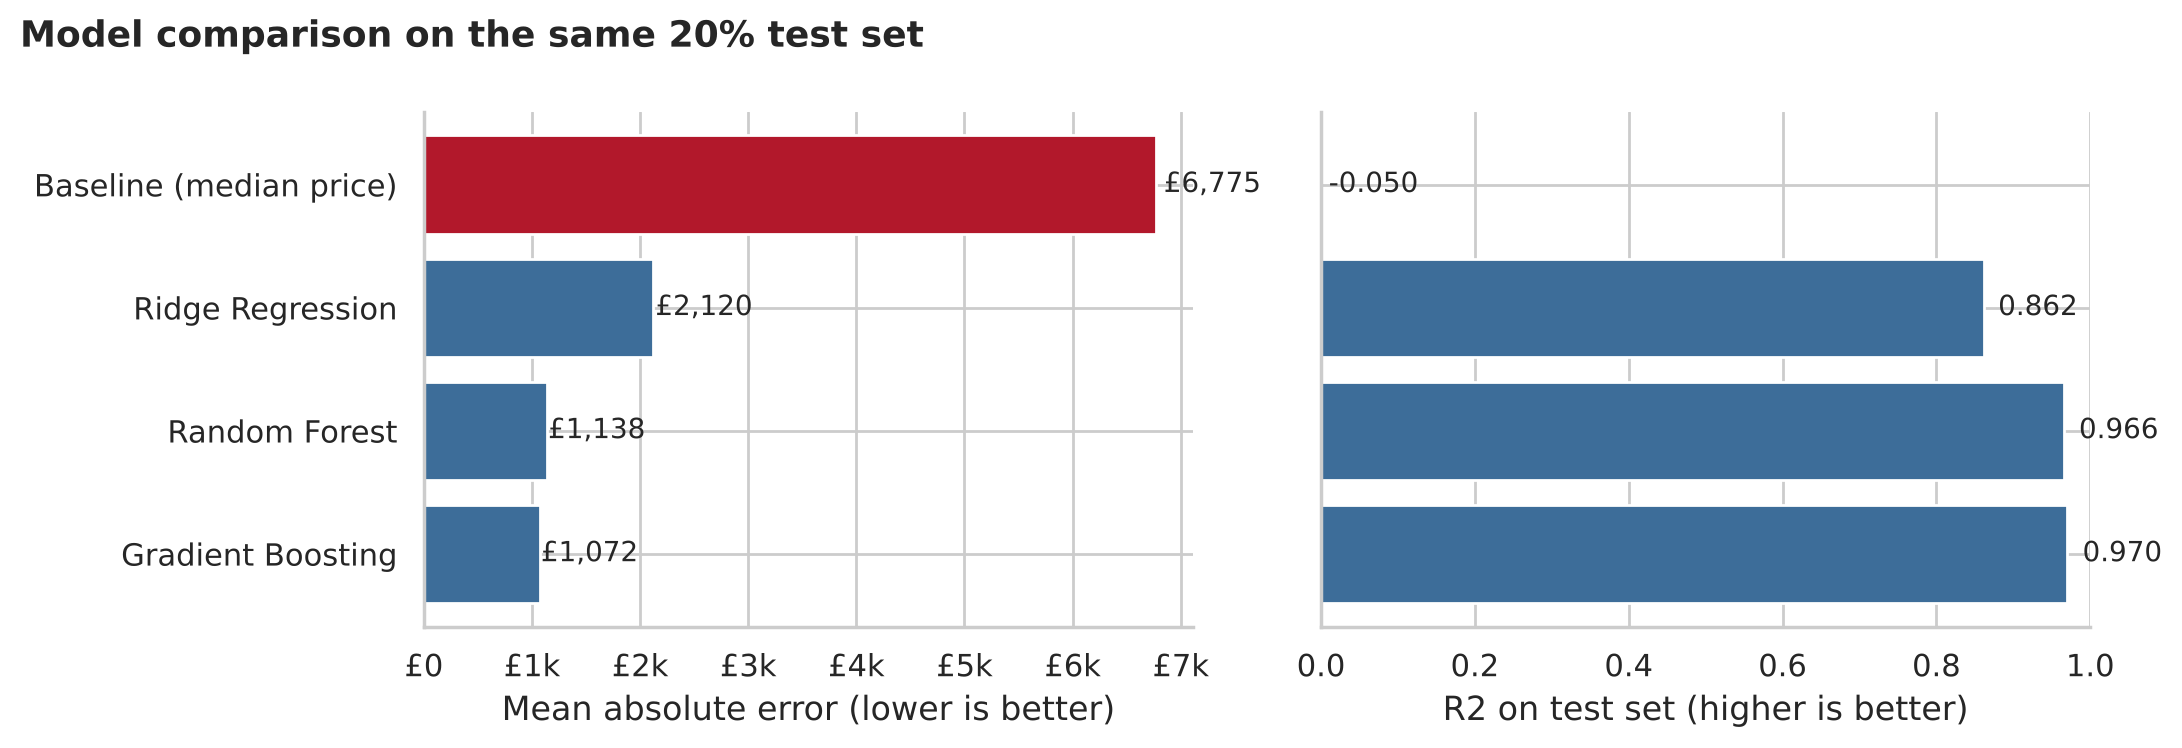

In [20]:
save(plot_model_comparison(comparison), "model_comparison.png")

In [21]:
cv = cross_validate_final(df)
print(cv)
print(f"Mean R2: {cv.mean():.4f} (std {cv.std():.4f})")

fold 1    0.9706
fold 2    0.9652
fold 3    0.9626
fold 4    0.9684
fold 5    0.9598
dtype: float64
Mean R2: 0.9653 (std 0.0043)


### 7.3 Errors

In [22]:
preds = test_predictions(df)
print("Median absolute percentage error:", preds["abs_pct_error"].median(), "%")
print("Predictions within 10% of the real price:", round((preds["abs_pct_error"] <= 10).mean() * 100, 1), "%")

Median absolute percentage error: 5.2 %
Predictions within 10% of the real price: 79.1 %


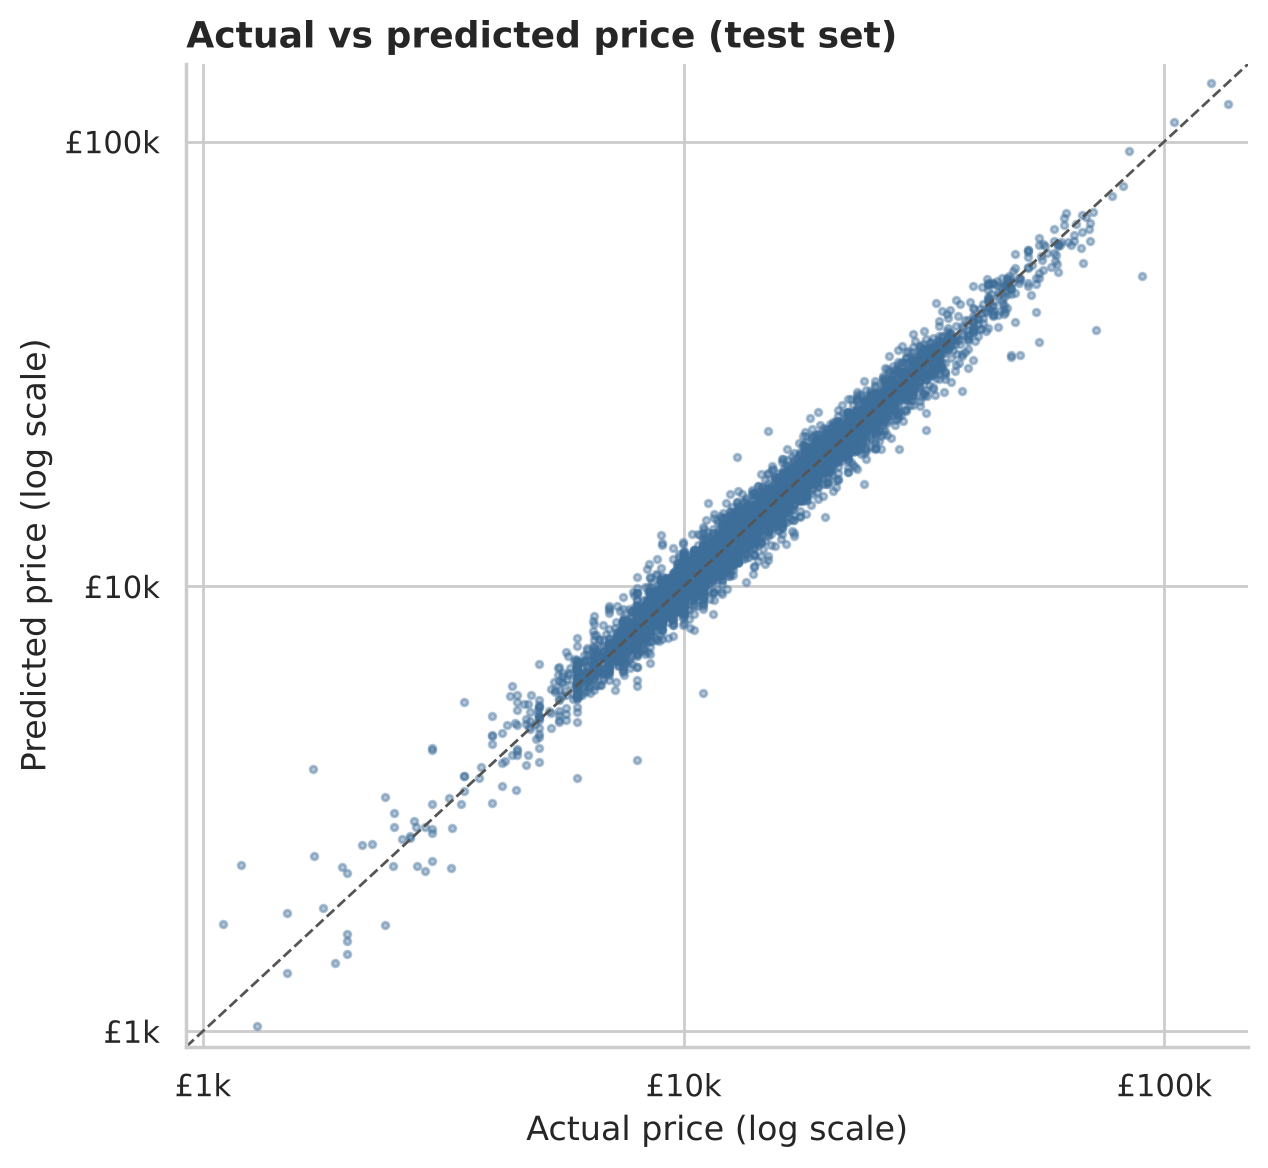

In [23]:
save(plot_actual_vs_predicted(preds), "actual_vs_predicted.png")

In [24]:
error_by(preds, "Manufacturer")

,Manufacturer,test_listings,MAE_gbp,median_abs_pct_error
0,Ford,3556,800.0,5.35
1,Volkswagen,2945,1040.0,4.90
2,Vauxhall,2616,687.0,5.50
3,Mercedes,2496,1505.0,4.60
4,BMW,2158,1496.0,5.40
5,Audi,2049,1560.0,5.50
6,Toyota,1361,718.0,4.50
7,Skoda,1231,926.0,5.60
8,Hyundai,934,788.0,5.10


### 7.4 Feature importance

In [25]:
importance = feature_importance(df)
importance.to_csv(RESULTS / "feature_importance.csv", index=False)
importance

,feature,MAE_increase_gbp
0,model,4057.0
1,age,2148.0
2,mileage,1124.0
3,engineSize,1115.0
4,mpg,718.0
5,transmission,502.0
6,fuelType,121.0
7,tax,58.0
8,Manufacturer,14.0


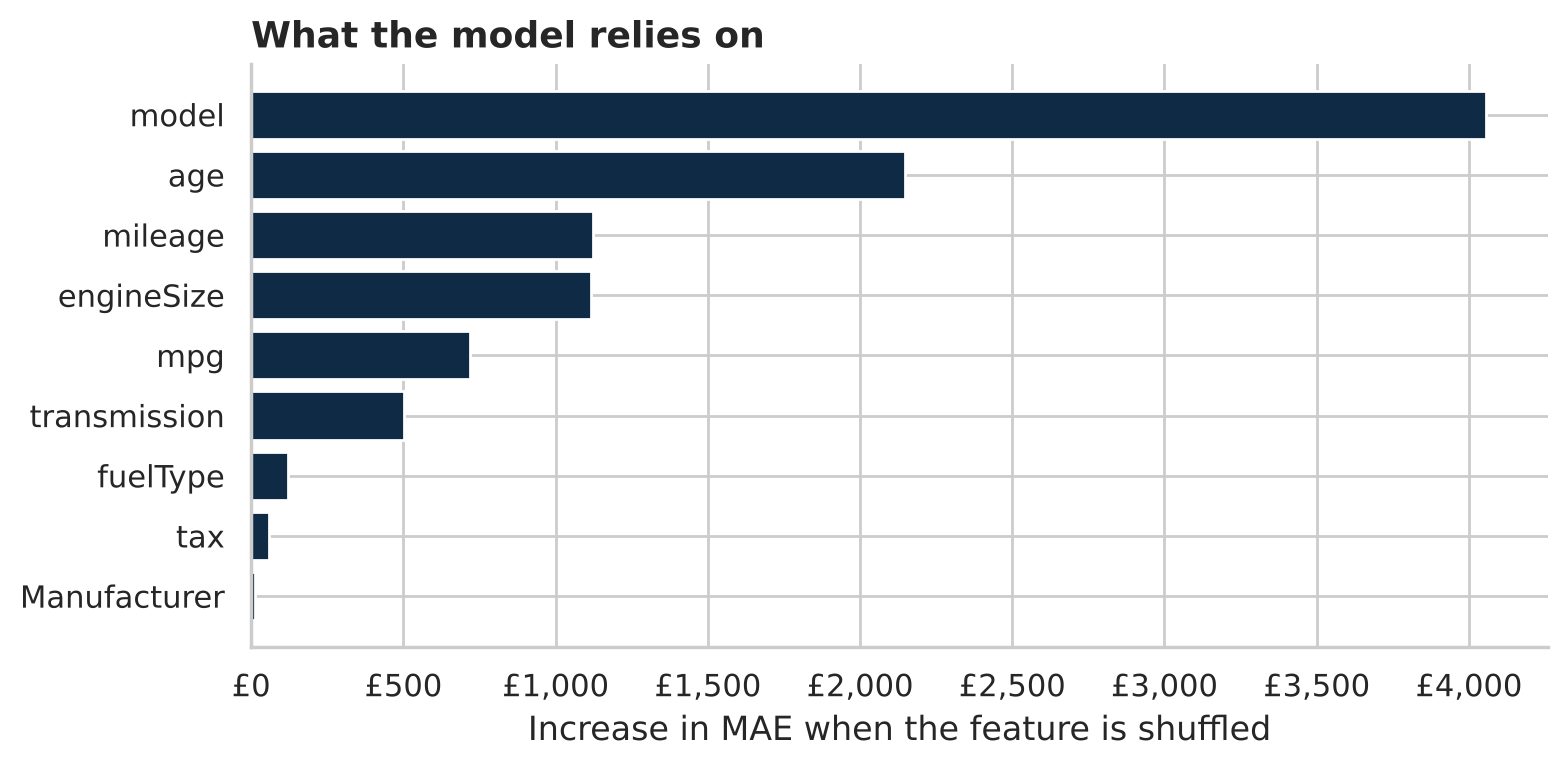

In [26]:
save(plot_feature_importance(importance), "feature_importance.png")

## 8. Findings

1. **Gradient Boosting prices cars to within 6.6% on average** (R2 0.970, mean absolute error £1,072). 79% of test predictions are within 10% of the real price, and 5-fold cross-validated R2 stays between 0.960 and 0.971.
2. **The car model matters most.** Shuffling it raises the error by about £4,000, then age (£2,100), mileage and engine size (about £1,100 each). Once the model is known, the manufacturer adds almost nothing.
3. **Cars lose half their value in the first two years.** The median price drops from £26,990 for cars under one year old to £14,095 at two years, and a 10-year-old car keeps 17%.
4. **Mercedes and Vauxhall hold value best over three years (62 to 64% kept); Toyota loses the most (42%).**
5. **Automatic and semi-automatic cars list for about twice the price of manuals** (median £19,250 and £22,265 against £11,000), and hybrids and diesels list above petrol cars.

**Limitations:** the data covers nine brands in 2020, so prices do not reflect later market changes, and it has no information on condition, service history or trim level, which explains part of the remaining error.